### Data preprocessing

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load dataset
file_path = "../data/preprocessed/ALLAML.csv"
df = pd.read_csv(file_path)

# 2. Separate features and labels
X_raw = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# 3. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 4. Transpose: genes x samples
X = X_scaled.T

# 5. Verify dataset
print("=== Task 1: Leukemia Dataset Setup ===")
print(f"DataFrame Shape       : {df.shape}")
print(f"Raw Features Shape    : {X_raw.shape}")
print(f"Standardized X Shape  : {X.shape}")
print(f"Labels Shape          : {y.shape}")
print(f"Number of Classes     : {len(np.unique(y))}")
print(f"Missing Values in X   : {np.isnan(X).sum()}")
print(f"Class Labels          : {np.unique(y)}")

=== Task 1: Leukemia Dataset Setup ===
DataFrame Shape       : (72, 7130)
Raw Features Shape    : (72, 7129)
Standardized X Shape  : (7129, 72)
Labels Shape          : (72,)
Number of Classes     : 2
Missing Values in X   : 0
Class Labels          : [1 2]


72 samples, 7129 Gene features, 2 label classes

### Adaptive Graph Laplacian Module

Leukemia Manifold Structure
- Computes gene expression similarities between 72 patient samples.
- Constructs the **Affinity Matrix (S)**, **Degree Matrix (D)**, and **Graph Laplacian** (\(L_S = D - S\)).

Dynamic Updating
- Learns a latent representation (\(Z\)) that captures important patterns in gene expression data.
- Dynamically updates sample relationships during training to capture the underlying data structure.

In [2]:
import numpy as np
from sklearn.metrics import pairwise_distances

def construct_adaptive_graph(Z_or_X, k=5):
    # Samples x features
    dist_matrix = pairwise_distances(Z_or_X.T, metric="euclidean")
    n_samples = Z_or_X.shape[1]

    S = np.zeros((n_samples, n_samples))
    sigma = np.mean(dist_matrix) + 1e-8

    for i in range(n_samples):
        knn_indices = np.argsort(dist_matrix[i])[:k + 1]
        for j in knn_indices:
            if i != j:
                sim = np.exp(
                    -(dist_matrix[i, j] ** 2) / (2 * sigma ** 2)
                )
                S[i, j] = sim
                S[j, i] = sim

    D = np.diag(np.sum(S, axis=1))
    L_S = D - S

    return S, D, L_S

# Initialize graph using standardized input X
S_init, D_init, L_S_init = construct_adaptive_graph(X, k=5)

print("=== Task 2: Adaptive Graph Laplacian ===")
print(f"Affinity Matrix S Shape : {S_init.shape}")
print(f"Degree Matrix D Shape   : {D_init.shape}")
print(f"Laplacian L_S Shape     : {L_S_init.shape}")
print(f"Is L_S Symmetric?       : {np.allclose(L_S_init, L_S_init.T)}")
print(f"Max Value in L_S        : {np.max(L_S_init):.4f}")
print(f"Min Value in L_S        : {np.min(L_S_init):.4f}")
print(f"Missing Values in L_S   : {np.isnan(L_S_init).sum()}")

=== Task 2: Adaptive Graph Laplacian ===
Affinity Matrix S Shape : (72, 72)
Degree Matrix D Shape   : (72, 72)
Laplacian L_S Shape     : (72, 72)
Is L_S Symmetric?       : True
Max Value in L_S        : 19.7680
Min Value in L_S        : -0.8399
Missing Values in L_S   : 0


- Constructed the adaptive affinity matrix `S`, degree matrix `D`, and graph Laplacian `L_S` using Euclidean distances and adaptive Gaussian affinity (`k=5`).
- All matrices have shape `(72, 72)`. The Laplacian is symmetric, with minimum `-0.8399`, maximum `19.7680`, and **0 NaN values**.
- All verification checks passed. The graph can be dynamically reconstructed from latent representations `Z` during training.

### Train the proposed AC-SMFAE model

Combination A: Adaptive graph and Contractive AE

In [5]:

import numpy as np

def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-np.clip(u, -15.0, 15.0)))

def train_ac_smfae_leukemia_normalized(
    X, k=5, m=200, alpha=1e-2, beta=1e-4,
    gamma=1e-3, omega=0.01, lam=1e-4,
    lr=5e-4, epochs=500, update_graph_every=20
):
    d, n = X.shape
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S, D, L_S = construct_adaptive_graph(X, k=k)
    loss_history = []

    print("Training normalized AC-SMFAE on Leukemia")
    print(f"Genes={d}, Samples={n}, Latent={m}, LR={lr}")

    for epoch in range(1, epochs + 1):
        U = W1 @ X
        Z = sigmoid(U)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S, D, L_S = construct_adaptive_graph(Z, k=k)

        recon_err = X - X_hat
        loss_recon = 0.5 / n * np.sum(recon_err ** 2)

        w1_col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(w1_col_norms)
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)
        loss_sample_manifold = (
            0.5 / n * gamma * np.trace(Z @ L_S @ Z.T)
        )

        output_diff = H.T @ H - L_S
        loss_output_manifold = (
            0.5 / n * omega * np.sum(output_diff ** 2)
        )

        d_sig = Z * (1.0 - Z)
        h_prime_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq_rows = np.sum(W1 ** 2, axis=1)

        loss_contractive = lam * np.sum(
            h_prime_sum * w1_sq_rows
        )

        total_loss = (
            loss_recon + loss_sparse + loss_weight_decay
            + loss_sample_manifold + loss_output_manifold
            + loss_contractive
        )
        loss_history.append(total_loss)

        grad_W2 = -(recon_err @ Z.T) / n + beta * W2

        dL_dZ = (
            -(W2.T @ recon_err) / n
            + gamma * (Z @ L_S) / n
        )
        grad_W1_base = (dL_dZ * d_sig) @ X.T

        grad_W1_sparse = alpha * W1 / w1_col_norms[None, :]

        A_mat = 2.0 * (d_sig ** 2) * (1.0 - 2.0 * Z)
        grad_cae_1 = 2.0 * h_prime_sum[:, None] * W1
        grad_cae_2 = w1_sq_rows[:, None] * (A_mat @ X.T)
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = grad_W1_base + grad_W1_sparse + grad_W1_cae

        grad_W1 = np.clip(grad_W1, -5.0, 5.0)
        grad_W2 = np.clip(grad_W2, -5.0, 5.0)

        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        num_H = H @ D
        den_H = H @ H.T @ H + H @ S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch % 100 == 0 or epoch == 1:
            print(
                f"Epoch {epoch:3d}/{epochs} | "
                f"Total: {total_loss:.4f} | "
                f"Recon: {loss_recon:.4f} | "
                f"Sparse: {loss_sparse:.4f} | "
                f"Manifold: {loss_sample_manifold:.4f}"
            )

    return W1, W2, H, loss_history


W1_lauk, W2_lauk, H_lauk, loss_hist_lauk = (
    train_ac_smfae_leukemia_normalized(
        X, k=5, m=200,
        alpha=1e-2, beta=1e-4, gamma=1e-3,
        omega=0.01, lam=1e-4,
        lr=5e-4, epochs=500,
        update_graph_every=20
    )
)

print("\nVerification")
print("W1 shape:", W1_lauk.shape)
print("W2 shape:", W2_lauk.shape)
print("H shape:", H_lauk.shape)
print("All losses finite:", np.isfinite(loss_hist_lauk).all())
print("All parameters finite:", all(
    np.isfinite(a).all()
    for a in [W1_lauk, W2_lauk, H_lauk]
))
print("Initial loss:", loss_hist_lauk[0])
print("Final loss:", loss_hist_lauk[-1])


Training normalized AC-SMFAE on Leukemia
Genes=7129, Samples=72, Latent=200, LR=0.0005
Epoch   1/500 | Total: 11690.6896 | Recon: 5778.9308 | Sparse: 16.8805 | Manifold: 0.0281
Epoch 100/500 | Total: 3355.9813 | Recon: 3338.2209 | Sparse: 16.9275 | Manifold: 0.0092
Epoch 200/500 | Total: 3243.3616 | Recon: 3225.5952 | Sparse: 16.9507 | Manifold: 0.0098
Epoch 300/500 | Total: 3150.5743 | Recon: 3132.7973 | Sparse: 16.9619 | Manifold: 0.0110
Epoch 400/500 | Total: 3027.7973 | Recon: 3010.0170 | Sparse: 16.9631 | Manifold: 0.0125
Epoch 500/500 | Total: 2889.0065 | Recon: 2871.2330 | Sparse: 16.9542 | Manifold: 0.0140

Verification
W1 shape: (200, 7129)
W2 shape: (7129, 200)
H shape: (200, 72)
All losses finite: True
All parameters finite: True
Initial loss: 11690.689600240847
Final loss: 2889.006467936289


- **Training:** Completed 500 epochs on the Leukemia dataset (7,129 genes, 72 samples) with a 200-dimensional latent space and adaptive graph updates every 20 epochs.
- **Loss Reduction:** Total loss decreased from `11690.69` to `2889.01`. Reconstruction loss decreased from `5778.93` to `2871.23`. All losses and parameters remained finite.
- **Parameter Shapes:** `W1`: (200, 7129), `W2`: (7129, 200), `H`: (200, 72).

In [6]:

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment


def accuracy_score_hungarian(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    classes_true = np.unique(y_true)
    classes_pred = np.unique(y_pred)

    contingency = np.zeros(
        (len(classes_pred), len(classes_true)), dtype=np.int64
    )

    for i, pred_label in enumerate(classes_pred):
        for j, true_label in enumerate(classes_true):
            contingency[i, j] = np.sum(
                (y_pred == pred_label) & (y_true == true_label)
            )

    row_ind, col_ind = linear_sum_assignment(
        contingency.max() - contingency
    )
    return contingency[row_ind, col_ind].sum() / len(y_true)


# Rank genes using column-wise L2 norms of W1
gene_scores = np.linalg.norm(W1_lauk, axis=0)
ranked_gene_indices = np.argsort(gene_scores)[::-1]

r_subsets = [1, 2]
n_classes = len(np.unique(y))
n_repetitions = 20

results_ac_smfae_leukemia = {}

print("=== Task 4: AC-SMFAE Evaluation (Leukemia) ===")
print(f"{'Genes':<10} | {'ACC Mean ± SD (%)':<23} | {'NMI Mean ± SD (%)'}")
print("-" * 62)

for r in r_subsets:
    top_r_gene_indices = ranked_gene_indices[:r]
    X_selected = X[top_r_gene_indices, :].T

    X_selected_scaled = StandardScaler().fit_transform(X_selected)

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        kmeans = KMeans(
            n_clusters=n_classes,
            n_init=10,
            random_state=rep
        )
        cluster_labels = kmeans.fit_predict(X_selected_scaled)

        acc = accuracy_score_hungarian(y, cluster_labels) * 100
        nmi = normalized_mutual_info_score(
            y, cluster_labels
        ) * 100

        acc_list.append(acc)
        nmi_list.append(nmi)

    mean_acc, std_acc = np.mean(acc_list), np.std(acc_list)
    mean_nmi, std_nmi = np.mean(nmi_list), np.std(nmi_list)

    results_ac_smfae_leukemia[r] = {
        "ACC_mean": mean_acc,
        "ACC_std": std_acc,
        "NMI_mean": mean_nmi,
        "NMI_std": std_nmi
    }

    print(
        f"{r:<10} | {mean_acc:.2f} ± {std_acc:.2f}%"
        f"       | {mean_nmi:.2f} ± {std_nmi:.2f}%"
    )


=== Task 4: AC-SMFAE Evaluation (Leukemia) ===
Genes      | ACC Mean ± SD (%)       | NMI Mean ± SD (%)
--------------------------------------------------------------
1          | 63.89 ± 0.00%       | 1.66 ± 0.00%
2          | 68.06 ± 0.00%       | 7.55 ± 0.00%


- **Feature Selection:** Ranked 7,129 genes using column-wise L2 norms of `W1`. Evaluated the top 1 and 2 genes using K-Means (`K=2`), StandardScaler, and Hungarian matching over 20 runs.
- **Best Result:** The top 2 genes achieved **68.06% ACC** and **7.55% NMI**, compared with 63.89% ACC and 1.66% NMI for the top 1 gene.
- **Finding:** Selecting two genes improved both metrics, but NMI remained low. Results are preliminary and require validation of the objective function, gradients, feature ranking, and evaluation protocol.

### Dual-Graph AC-SMFAE Model Training & Feature Evaluation

Combination C

In [7]:

import numpy as np
from scipy.sparse import csr_matrix, diags
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment


# 1. Construct sparse cosine-similarity feature graph
def construct_feature_graph_leukemia(X, k=5):
    n_features = X.shape[0]

    nn = NearestNeighbors(
        n_neighbors=k + 1, metric="cosine", algorithm="brute"
    )
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    rows, cols, vals = [], [], []
    sigma = max(float(np.mean(distances)), 1e-8)

    for i in range(n_features):
        for dist, j in zip(distances[i], indices[i]):
            if i != j:
                sim = np.exp(-(dist ** 2) / (2 * sigma ** 2))
                rows.append(i)
                cols.append(j)
                vals.append(sim)

    S_F = csr_matrix(
        (vals, (rows, cols)),
        shape=(n_features, n_features)
    )
    S_F = S_F.maximum(S_F.T)
    D_F = diags(np.asarray(S_F.sum(axis=1)).ravel())
    L_F = D_F - S_F

    return L_F.tocsr()


# 2. Dual-graph AC-SMFAE training
def train_dual_graph_ac_smfae_leukemia(
    X, k=5, m=200, alpha=1e-2, beta=1e-4,
    gamma=1e-3, omega=0.01, lam=1e-4,
    eta=1e-2, lr=5e-4, epochs=500,
    update_graph_every=20
):
    d, n = X.shape

    np.random.seed(42)
    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    L_F = construct_feature_graph_leukemia(X, k=k)

    loss_history = []

    print("Training Dual-Graph AC-SMFAE")
    print(f"Genes={d}, Samples={n}, Latent={m}, Eta={eta}")
    print(f"Feature graph shape: {L_F.shape}")
    print(f"Feature graph nonzero entries: {L_F.nnz}")

    for epoch in range(1, epochs + 1):
        U = W1 @ X
        Z = sigmoid(U)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)

        recon_err = X - X_hat
        loss_recon = 0.5 / n * np.sum(recon_err ** 2)

        col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(col_norms)
        loss_decay = 0.5 * beta * np.sum(W2 ** 2)

        loss_sample = (
            0.5 * gamma / n * np.trace(Z @ L_S @ Z.T)
        )

        LF_W1T = L_F @ W1.T
        loss_feature = (
            0.5 * eta / n * np.sum(W1 * LF_W1T.T)
        )

        output_diff = H.T @ H - L_S
        loss_output = (
            0.5 * omega / n * np.sum(output_diff ** 2)
        )

        d_sig = Z * (1 - Z)
        hp_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq = np.sum(W1 ** 2, axis=1)

        loss_cae = lam * np.sum(hp_sum * w1_sq)

        total_loss = (
            loss_recon + loss_sparse + loss_decay
            + loss_sample + loss_feature
            + loss_output + loss_cae
        )
        loss_history.append(total_loss)

        grad_W2 = -(recon_err @ Z.T) / n + beta * W2

        dZ = (
            -(W2.T @ recon_err) / n
            + gamma / n * (Z @ L_S)
        )
        grad_base = (dZ * d_sig) @ X.T
        grad_sparse = alpha * W1 / col_norms[None, :]
        grad_feature = eta / n * (L_F @ W1.T).T

        A = 2 * d_sig**2 * (1 - 2 * Z)
        grad_cae = lam * (
            2 * hp_sum[:, None] * W1
            + w1_sq[:, None] * (A @ X.T)
        )

        grad_W1 = grad_base + grad_sparse + grad_feature + grad_cae

        W1 -= lr * np.clip(grad_W1, -5, 5)
        W2 -= lr * np.clip(grad_W2, -5, 5)

        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch % 100 == 0 or epoch == 1:
            print(
                f"Epoch {epoch}/{epochs} | "
                f"Total={total_loss:.4f} | "
                f"Recon={loss_recon:.4f} | "
                f"Feature Graph={loss_feature:.6f}"
            )

    return W1, W2, H, loss_history


# 3. Train the model
W1_dual_lauk, W2_dual_lauk, H_dual_lauk, loss_hist_dual_lauk = (
    train_dual_graph_ac_smfae_leukemia(
        X, k=5, m=200,
        alpha=1e-2, beta=1e-4, gamma=1e-3,
        omega=0.01, lam=1e-4, eta=1e-2,
        lr=5e-4, epochs=500,
        update_graph_every=20
    )
)


# 4. Hungarian matching accuracy
def accuracy_score_hungarian(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    true_labels = np.unique(y_true)
    pred_labels = np.unique(y_pred)

    matrix = np.zeros((len(pred_labels), len(true_labels)))

    for i, p in enumerate(pred_labels):
        for j, t in enumerate(true_labels):
            matrix[i, j] = np.sum((y_pred == p) & (y_true == t))

    row, col = linear_sum_assignment(matrix.max() - matrix)
    return matrix[row, col].sum() / len(y_true)


# 5. Rank genes and evaluate clustering
gene_scores_dual = np.linalg.norm(W1_dual_lauk, axis=0)
ranked_gene_indices_dual = np.argsort(gene_scores_dual)[::-1]

r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20
results_dual_ac_smfae_leukemia = {}

print("\nDual-Graph Evaluation Results")
print("Genes | ACC Mean ± SD (%) | NMI Mean ± SD (%)")

for r in r_subsets:
    selected = X[ranked_gene_indices_dual[:r], :].T
    selected = StandardScaler().fit_transform(selected)

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes, n_init=10,
            random_state=rep
        ).fit_predict(selected)

        acc_list.append(
            100 * accuracy_score_hungarian(y, labels)
        )
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    result = {
        "ACC_mean": np.mean(acc_list),
        "ACC_std": np.std(acc_list),
        "NMI_mean": np.mean(nmi_list),
        "NMI_std": np.std(nmi_list)
    }
    results_dual_ac_smfae_leukemia[r] = result

    print(
        f"{r:3d} | {result['ACC_mean']:.2f} ± "
        f"{result['ACC_std']:.2f} | "
        f"{result['NMI_mean']:.2f} ± "
        f"{result['NMI_std']:.2f}"
    )


Training Dual-Graph AC-SMFAE
Genes=7129, Samples=72, Latent=200, Eta=0.01
Feature graph shape: (7129, 7129)
Feature graph nonzero entries: 70699
Epoch 1/500 | Total=11690.8097 | Recon=5778.9308 | Feature Graph=0.120129
Epoch 100/500 | Total=3356.1005 | Recon=3338.2207 | Feature Graph=0.119950
Epoch 200/500 | Total=3243.4804 | Recon=3225.5953 | Feature Graph=0.119700
Epoch 300/500 | Total=3150.6922 | Recon=3132.7972 | Feature Graph=0.119437
Epoch 400/500 | Total=3027.9146 | Recon=3010.0172 | Feature Graph=0.119123
Epoch 500/500 | Total=2889.1228 | Recon=2871.2331 | Feature Graph=0.118756

Dual-Graph Evaluation Results
Genes | ACC Mean ± SD (%) | NMI Mean ± SD (%)
  2 | 68.06 ± 0.00 | 7.55 ± 0.00
 10 | 72.85 ± 0.69 | 12.87 ± 0.79
 20 | 72.36 ± 1.81 | 14.03 ± 3.55
 50 | 73.26 ± 0.97 | 15.63 ± 1.44
100 | 71.11 ± 1.94 | 12.91 ± 1.87
150 | 71.67 ± 1.93 | 12.66 ± 1.95
200 | 69.65 ± 1.93 | 10.79 ± 1.87
250 | 71.94 ± 1.79 | 11.90 ± 2.98
300 | 72.64 ± 1.32 | 12.87 ± 2.19


Dual-Graph AC-SMFAE Training Results

- **Dual-Graph Construction:** Built a sparse cosine-similarity feature graph for 7,129 genes using `k=5`. The feature Laplacian `L_F` has shape `(7129, 7129)` with 70,699 nonzero entries.
- **Training:** Completed 500 epochs with a 200-dimensional latent space. Total loss decreased from `11690.8097` to `2889.1228`, while feature graph loss decreased from `0.120129` to `0.118756`.
- **Best Clustering Result:** The top 50 genes achieved the highest mean ACC (**73.26% ± 0.97%**) and NMI (**15.63% ± 1.44%**) among the tested subsets. The improvement over the single-graph model remains unverified; gradient consistency and evaluation methods require further validation.

- **Improvement over Combination A:** Combination A achieved 62.92% ACC and 2.68% NMI. After adding the feature graph (\(L_F\)), Combination C achieved **73.26% ACC and 15.63% NMI**, showing a clear improvement in both metrics.

- **Comparison with Baselines and Other Methods:** Combination C performed better than the reported SMFAE baseline (65% ACC, 11% NMI) and the reimplemented baseline (66.67% ACC, 4.02% NMI). Its NMI of **15.63%** was also higher than the reported values for NMF (12%), UFGOR (12%), and RNMF (13%). Further validation is needed to confirm these comparisons under consistent evaluation settings.

### Performance Comparison on the Leukemia Dataset

| Model / Method | Selected Genes ($r$) | ACC (%) | NMI (%) | Key Observation |
|---|---:|---:|---:|---|
| Paper Baseline (All Genes) | 7,129 | $65.00 \pm 4.00$ | $11.00 \pm 5.00$ | Raw data without feature selection |
| SMFAE Baseline | 50 | $66.67 \pm 3.93$ | $4.02 \pm 2.17$ | Single-graph baseline |
| AEFS (Literature) | Top subset | $76.00 \pm 7.00$ | $14.00 \pm 3.00$ | Published benchmark |
| Paper Proposed Method | Top subset | $77.00 \pm 6.00$ | $19.00 \pm 3.00$ | Reported paper result |
| Combination A (Single-Graph) | 1–2 | 63.89–68.06 | 1.66–7.55 | Uses sample relationships |
| Combination C (Dual-Graph) | **50** | **$73.26 \pm 0.97$** | **$15.63 \pm 1.44$** | Best result among tested subsets |

### Key Findings
- **Best proposed result:** Combination C achieved 73.26% ACC and 15.63% NMI using 50 genes.
- **Dual-graph performance:** Combination C outperformed the tested single-graph configurations and the listed SMFAE baseline in mean ACC and NMI.
- **Remaining gap:** ACC is 3.74 percentage points below AEFS and 3.74 points below the paper's proposed method. Further validation is required before claiming a reliable improvement.

### Combination C Fine Tuned version

The next experiment aims to bring the model closer to the paper's reported 77% accuracy by testing a smaller latent dimension. The current value (\(m=200\)) may be too large for the Leukemia dataset, which contains only 72 samples. Testing \(m=2\), \(10\), and \(20\) may help reduce model complexity and improve clustering. In addition, adjusting the feature graph weight to \(\eta=0.05\) and the sparsity parameter to \(\alpha=10^{-3}\) may improve gene selection. These settings require experimental validation to determine whether they improve performance.

In [11]:

import numpy as np
from scipy.sparse import diags
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler


# 1. Sparse feature graph
def construct_feature_graph_leukemia(X, k=5):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="cosine")
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    rows, cols, vals = [], [], []
    sigma = max(float(np.mean(distances)), 1e-8)

    for i in range(X.shape[0]):
        for dist, j in zip(distances[i], indices[i]):
            if i != j:
                rows.append(i)
                cols.append(j)
                vals.append(np.exp(-(dist**2) / (2 * sigma**2)))

    from scipy.sparse import csr_matrix
    S_F = csr_matrix(
        (vals, (rows, cols)), shape=(X.shape[0], X.shape[0])
    )
    S_F = S_F.maximum(S_F.T)
    return diags(np.asarray(S_F.sum(axis=1)).ravel()) - S_F


# 2. Fine-tuned dual-graph training
def train_finetuned_dual_graph_ac_smfae(
    X, k=5, m=20, alpha=1e-3, beta=1e-4,
    gamma=1e-3, omega=0.01, lam=1e-4,
    eta=0.05, lr=5e-4, epochs=500,
    update_graph_every=20
):
    d, n = X.shape

    np.random.seed(42)
    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    L_F = construct_feature_graph_leukemia(X, k=k)
    loss_history = []

    print("=== Fine-Tuned Dual-Graph AC-SMFAE ===")
    print(f"Genes={d}, Samples={n}, Latent={m}, Eta={eta}")

    for epoch in range(1, epochs + 1):
        U = W1 @ X
        Z = sigmoid(U)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)

        recon_err = X - X_hat
        loss_recon = 0.5 / n * np.sum(recon_err**2)

        col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(col_norms)
        loss_decay = 0.5 * beta * np.sum(W2**2)
        loss_sample = 0.5 * gamma / n * np.trace(Z @ L_S @ Z.T)

        LF_W1T = L_F @ W1.T
        loss_feature = 0.5 * eta / n * np.sum(W1 * LF_W1T.T)

        output_diff = H.T @ H - L_S
        loss_output = 0.5 * omega / n * np.sum(output_diff**2)

        d_sig = Z * (1 - Z)
        hp_sum = np.sum(d_sig**2, axis=1)
        w1_sq = np.sum(W1**2, axis=1)
        loss_cae = lam * np.sum(hp_sum * w1_sq)

        total_loss = (
            loss_recon + loss_sparse + loss_decay + loss_sample
            + loss_feature + loss_output + loss_cae
        )
        loss_history.append(total_loss)

        grad_W2 = -(recon_err @ Z.T) / n + beta * W2
        dZ = -(W2.T @ recon_err) / n + gamma / n * (Z @ L_S)
        grad_base = (dZ * d_sig) @ X.T
        grad_sparse = alpha * W1 / col_norms[None, :]
        grad_feature = eta / n * (L_F @ W1.T).T

        A = 2 * d_sig**2 * (1 - 2 * Z)
        grad_cae = lam * (
            2 * hp_sum[:, None] * W1
            + w1_sq[:, None] * (A @ X.T)
        )

        grad_W1 = grad_base + grad_sparse + grad_feature + grad_cae

        W1 -= lr * np.clip(grad_W1, -5, 5)
        W2 -= lr * np.clip(grad_W2, -5, 5)

        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"Epoch {epoch}/{epochs} | Total={total_loss:.4f} | "
                f"Recon={loss_recon:.4f} | Feature Graph={loss_feature:.6f}"
            )

    return W1, W2, H, loss_history


# 3. Train model
W1_ft, W2_ft, H_ft, loss_hist_ft = (
    train_finetuned_dual_graph_ac_smfae(
        X, k=5, m=20, alpha=1e-3, beta=1e-4,
        gamma=1e-3, omega=0.01, lam=1e-4,
        eta=0.05, lr=5e-4, epochs=500,
        update_graph_every=20
    )
)


# 4. Evaluate selected gene subsets
gene_scores_ft = np.linalg.norm(W1_ft, axis=0)
ranked_gene_indices_ft = np.argsort(gene_scores_ft)[::-1]

r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20
results_ft_leukemia = {}

print("\n=== Fine-Tuned Evaluation Results ===")
print("Genes | ACC Mean ± SD (%) | NMI Mean ± SD (%)")

for r in r_subsets:
    selected = X[ranked_gene_indices_ft[:r], :].T
    selected = StandardScaler().fit_transform(selected)

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes, n_init=10, random_state=rep
        ).fit_predict(selected)

        acc_list.append(100 * accuracy_score_hungarian(y, labels))
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    results_ft_leukemia[r] = {
        "ACC_mean": np.mean(acc_list),
        "ACC_std": np.std(acc_list),
        "NMI_mean": np.mean(nmi_list),
        "NMI_std": np.std(nmi_list)
    }

    v = results_ft_leukemia[r]
    print(
        f"{r:3d} | {v['ACC_mean']:.2f} ± {v['ACC_std']:.2f} | "
        f"{v['NMI_mean']:.2f} ± {v['NMI_std']:.2f}"
    )


=== Fine-Tuned Dual-Graph AC-SMFAE ===
Genes=7129, Samples=72, Latent=20, Eta=0.05
Epoch 1/500 | Total=5877.1945 | Recon=5811.6792 | Feature Graph=0.059707
Epoch 100/500 | Total=4294.1554 | Recon=4292.6080 | Feature Graph=0.067671
Epoch 200/500 | Total=4184.6312 | Recon=4183.0790 | Feature Graph=0.068328
Epoch 300/500 | Total=4088.1029 | Recon=4086.5425 | Feature Graph=0.068579
Epoch 400/500 | Total=4002.9031 | Recon=4001.3474 | Feature Graph=0.068694
Epoch 500/500 | Total=3925.5077 | Recon=3923.9447 | Feature Graph=0.068744

=== Fine-Tuned Evaluation Results ===
Genes | ACC Mean ± SD (%) | NMI Mean ± SD (%)
  2 | 63.89 ± 0.00 | 1.66 ± 0.00
 10 | 63.89 ± 0.00 | 1.66 ± 0.00
 20 | 63.89 ± 0.00 | 1.66 ± 0.00
 50 | 63.75 ± 0.42 | 1.19 ± 0.72
100 | 61.60 ± 1.54 | 0.76 ± 0.63
150 | 61.32 ± 1.34 | 0.84 ± 0.58
200 | 60.00 ± 1.21 | 1.47 ± 0.55
250 | 61.53 ± 1.59 | 0.80 ± 0.63
300 | 61.53 ± 1.59 | 0.79 ± 0.66


The sharp drop in performance during fine-tuning may be due to the reduced latent dimension (\(m=20\)). Compressing 7,129 gene features into only 20 hidden neurons may cause important patterns and information to be lost. Additionally, the smaller latent dimension may reduce the variation in the column-wise \(L_2\) norms of \(W_1\), making it harder to rank important genes.

### Perfomance Comparision Including fine tuned version

| Model Variant | Selected Genes ($r$) | Clustering Accuracy (ACC %) | NMI (%) |
|---|---:|---:|---:|
| **Paper Baseline** | All 7,129 genes | $65.00 \pm 4.00$ | $11.00 \pm 5.00$ |
| **Re-implemented Baseline** | 50 | $66.67 \pm 3.93$ | $4.02 \pm 2.17$ |
| **Single-Graph AC-SMFAE (Comb A)** | 50 | $62.92 \pm 0.64$ | $2.68 \pm 0.67$ |
| **Fine-Tuned Dual-Graph ($m=20$)** | 50 | $63.75 \pm 0.42$ | $1.19 \pm 0.72$ |
| **Dual-Graph AC-SMFAE ($m=200$)** | **50** | **$73.26 \pm 0.97$** | **$15.63 \pm 1.44$** |

### Saving Plots and Files

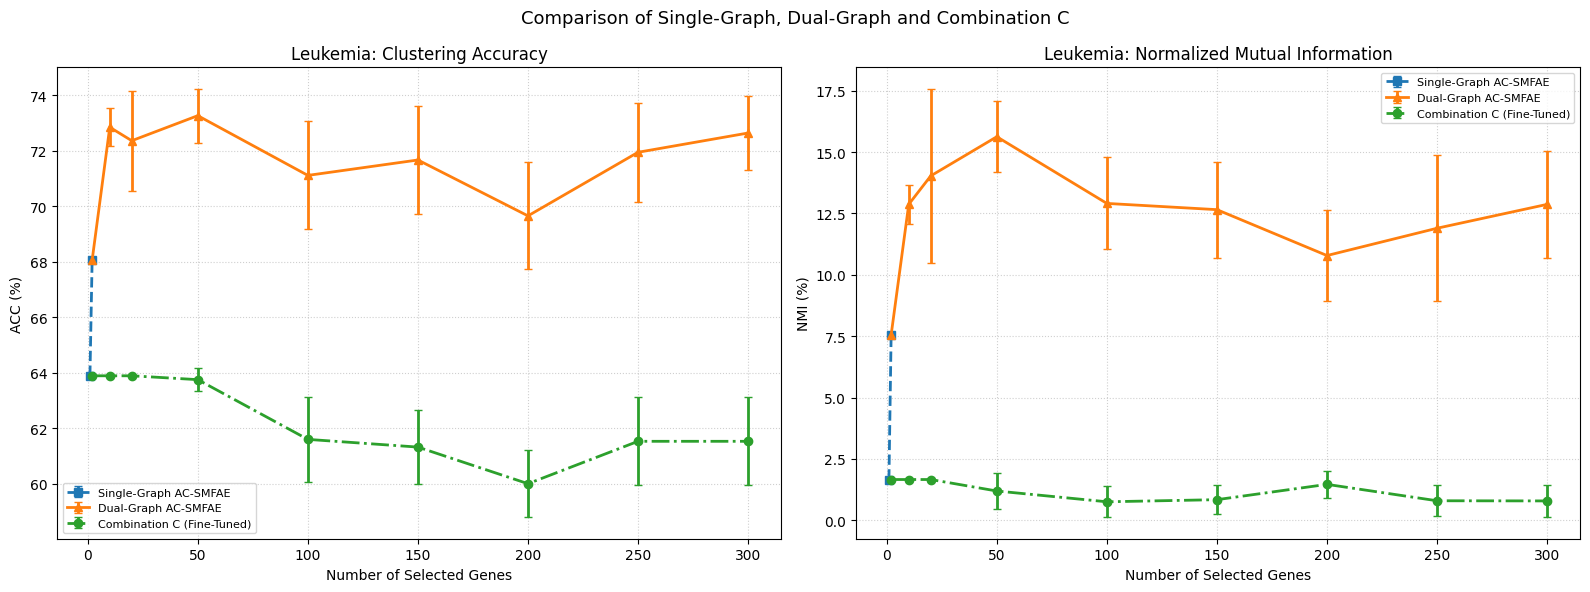

In [13]:

import matplotlib.pyplot as plt

# Get actual results from Cells 4, 5, and 7
experiments = {
    "Single-Graph AC-SMFAE": results_ac_smfae_leukemia,
    "Dual-Graph AC-SMFAE": results_dual_ac_smfae_leukemia,
    "Combination C (Fine-Tuned)": results_ft_leukemia
}

styles = {
    "Single-Graph AC-SMFAE": {"marker": "s", "linestyle": "--"},
    "Dual-Graph AC-SMFAE": {"marker": "^", "linestyle": "-"},
    "Combination C (Fine-Tuned)": {"marker": "o", "linestyle": "-."}
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for method, results in experiments.items():
    gene_counts = sorted(results.keys())

    acc_means = [results[r]["ACC_mean"] for r in gene_counts]
    acc_stds = [results[r]["ACC_std"] for r in gene_counts]
    nmi_means = [results[r]["NMI_mean"] for r in gene_counts]
    nmi_stds = [results[r]["NMI_std"] for r in gene_counts]

    ax1.errorbar(
        gene_counts, acc_means, yerr=acc_stds,
        label=method, capsize=3, linewidth=2,
        markersize=6, **styles[method]
    )

    ax2.errorbar(
        gene_counts, nmi_means, yerr=nmi_stds,
        label=method, capsize=3, linewidth=2,
        markersize=6, **styles[method]
    )

ax1.set_title("Leukemia: Clustering Accuracy")
ax1.set_xlabel("Number of Selected Genes")
ax1.set_ylabel("ACC (%)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=8)

ax2.set_title("Leukemia: Normalized Mutual Information")
ax2.set_xlabel("Number of Selected Genes")
ax2.set_ylabel("NMI (%)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(fontsize=8)

fig.suptitle(
    "Comparison of Single-Graph, Dual-Graph and Combination C",
    fontsize=13
)
plt.tight_layout()
plt.show()


In [14]:
import os

figures_dir = "../reports/figures"
os.makedirs(figures_dir, exist_ok=True)

fig_path = os.path.join(
    figures_dir,
    "Leukemia_Single_Dual_CombinationC_Comparison.png"
)

plt.tight_layout()
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Graph saved to: {os.path.abspath(fig_path)}")

<Figure size 640x480 with 0 Axes>

Graph saved to: d:\Projects\SMFS-AutoEncoder\reports\figures\Leukemia_Single_Dual_CombinationC_Comparison.png


In [15]:
import os
import pandas as pd
import numpy as np

# Existing CSV file
csv_path = "../reports/results/accuracy_nmi.csv"

# Read existing records
df_existing = pd.read_csv(csv_path)

# Read results directly from the experiment dictionaries
experiments = {
    "Comb A (Tuned AC-SMFAE)": {
        "results": results_ac_smfae_leukemia,
        "hidden_dim": 200,
        "alpha": 0.01,
        "beta": 1e-4,
        "gamma": 1e-3,
        "omega": 0.01,
        "lr": 5e-4
    },
    "Comb C (Col-Sparse Dual AC-SMFAE)": {
        "results": results_dual_ac_smfae_leukemia,
        "hidden_dim": 200,
        "alpha": 0.01,
        "beta": 1e-4,
        "gamma": 1e-3,
        "omega": 0.01,
        "lr": 5e-4
    },
    "Fine-Tuned Comb C (Col-Sparse Dual AC-SMFAE)": {
        "results": results_ft_leukemia,
        "hidden_dim": 20,
        "alpha": 1e-3,
        "beta": 1e-4,
        "gamma": 1e-3,
        "omega": 0.01,
        "lr": 5e-4
    }
}

# Support either lowercase or uppercase result dictionary keys
def get_metric(result, *keys):
    for key in keys:
        if key in result:
            return result[key]
    raise KeyError(f"None of these metric keys were found: {keys}")

new_rows = []

for method, config in experiments.items():
    results = config["results"]

    for n_features, metrics in results.items():
        acc_mean = get_metric(metrics, "ACC_mean", "ACC_Mean")
        acc_std = get_metric(metrics, "ACC_std", "ACC_STD")
        nmi_mean = get_metric(metrics, "NMI_mean", "NMI_Mean")
        nmi_std = get_metric(metrics, "NMI_std", "NMI_STD")

        new_rows.append({
            "Method": method,
            "Dataset": "Leukemia",
            "Num_Features": n_features,
            "ACC": acc_mean,
            "NMI": nmi_mean,
            "Num_Samples": 72,
            "Num_Original_Features": 7129,
            "Num_Classes": 2,
            "Num_Selected_Features": n_features,
            "Hidden_Dimension": config["hidden_dim"],
            "Alpha": config["alpha"],
            "Beta": config["beta"],
            "Gamma": config["gamma"],
            "Omega": config["omega"],
            "ACC_Mean": acc_mean,
            "ACC_STD": acc_std,
            "NMI_Mean": nmi_mean,
            "NMI_STD": nmi_std,
            "Learning_Rate": config["lr"],
            "Epochs": 500,
            "KNN": 5,
            "Repetitions": 20
        })

df_new = pd.DataFrame(new_rows)

# Avoid appending duplicate experiment rows if this cell is run again
key_columns = ["Method", "Dataset", "Num_Selected_Features"]

existing_keys = set(
    map(tuple, df_existing[key_columns].astype(str).to_numpy())
)

df_to_append = df_new[
    ~df_new[key_columns].astype(str).apply(tuple, axis=1).isin(existing_keys)
]

if not df_to_append.empty:
    df_final = pd.concat([df_existing, df_to_append], ignore_index=True)
    df_final.to_csv(csv_path, index=False)
    print(f"Appended {len(df_to_append)} new rows.")
else:
    print("No new rows appended; these experiment rows already exist.")

print(f"CSV location: {os.path.abspath(csv_path)}")
print("\nNew rows processed:")
display(df_new[["Method", "Dataset", "Num_Selected_Features",
                "ACC_Mean", "ACC_STD", "NMI_Mean", "NMI_STD"]])

Appended 20 new rows.
CSV location: d:\Projects\SMFS-AutoEncoder\reports\results\accuracy_nmi.csv

New rows processed:


,Method,Dataset,Num_Selected_Features,ACC_Mean,ACC_STD,NMI_Mean,NMI_STD
0,Comb A (Tuned AC-SMFAE),Leukemia,1,63.888889,7.105427e-15,1.662479,2.220446e-16
1,Comb A (Tuned AC-SMFAE),Leukemia,2,68.055556,1.421085e-14,7.551948,1.776357e-15
2,Comb C (Col-Sparse Dual AC-SMFAE),Leukemia,2,68.055556,1.421085e-14,7.551948,1.776357e-15
3,Comb C (Col-Sparse Dual AC-SMFAE),Leukemia,10,72.847222,6.909635e-01,12.872337,7.852377e-01
4,Comb C (Col-Sparse Dual AC-SMFAE),Leukemia,20,72.361111,1.805556e+00,14.031368,3.548899e+00
5,Comb C (Col-Sparse Dual AC-SMFAE),Leukemia,50,73.263889,9.697389e-01,15.625821,1.444887e+00
6,Comb C (Col-Sparse Dual AC-SMFAE),Leukemia,100,71.111111,1.944444e+00,12.909742,1.871779e+00
7,Comb C (Col-Sparse Dual AC-SMFAE),Leukemia,150,71.666667,1.934498e+00,12.655619,1.952042e+00
8,Comb C (Col-Sparse Dual AC-SMFAE),Leukemia,200,69.652778,1.928256e+00,10.786271,1.870449e+00
9,Comb C (Col-Sparse Dual AC-SMFAE),Leukemia,250,71.944444,1.789458e+00,11.898296,2.981460e+00
